Notebook to calculate the mean values of each variable from ERA5 in each region (for each month). Training is below.

In [151]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
import geopandas as gpd
from shapely.geometry import Point
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [14]:
# Read in the meteorological data
met_data = xr.open_dataset('DATA/GreenlandData/GreenlandMetData.nc')

# Read in the regions
mouginot_regions = gpd.read_file('DATA/GreenlandData/GL_regions_4326.gpkg')
mouginot_regions = mouginot_regions.set_index('label')
region_projections = mouginot_regions.to_crs(epsg=3413) # general purpose projection for polar regions

met_data
mouginot_regions

,cat,geometry
label,,
NO,4,"POLYGON ((-46.05111 82.71273, -46.05474 82.712..."
NE,3,"POLYGON ((-27.61115 80.77722, -27.61201 80.776..."
NW,5,"POLYGON ((-72.10705 78.0402, -72.10509 78.0404..."
CE,1,"POLYGON ((-28.9597 72.22443, -28.95929 72.2248..."
CW,2,"POLYGON ((-51.61965 71.81799, -51.61982 71.818..."
SE,6,"POLYGON ((-39.67038 68.63506, -39.67049 68.634..."
SW,7,"POLYGON ((-50.2405 68.22242, -50.23931 68.2224..."


In [19]:
## Find which ERA5 grid points fall within each region
# This can be used later to access any given variable at that point

lon_grid, lat_grid = np.meshgrid(met_data["longitude"].values, met_data["latitude"].values)
ilat, ilon = np.indices(lon_grid.shape)

lon_flat = lon_grid.ravel()
lat_flat = lat_grid.ravel()


#era5_points = gpd.GeoDataFrame(
#    geometry=gpd.points_from_xy(
#        lon_flat,
#        lat_flat
#    ),
#    crs='EPSG:4326'
#)
era5_points = gpd.GeoDataFrame(
    {
        "ilat": ilat.ravel(),
        "ilon": ilon.ravel(),
        "latitude": lat_grid.ravel(),
        "longitude": lon_grid.ravel()
    },
    geometry=gpd.points_from_xy(
        lon_grid.ravel(),
        lat_grid.ravel()
    ),
    crs="EPSG:4326"
)
era5_points_projected = era5_points.to_crs('EPSG:3413')

print(era5_points.head())

   ilat  ilon  latitude  longitude          geometry
0     0     0      86.0      -75.0    POINT (-75 86)
1     0     1      86.0      -74.9  POINT (-74.9 86)
2     0     2      86.0      -74.8  POINT (-74.8 86)
3     0     3      86.0      -74.7  POINT (-74.7 86)
4     0     4      86.0      -74.6  POINT (-74.6 86)


In [38]:
era5_regions = gpd.sjoin(
    era5_points_projected,
    region_projections,
    how="left",
    predicate="within"
)

print('ERA5 Points per Mouginot region: ')
print(era5_regions.groupby("label").size())


era5_regions

ERA5 Points per Mouginot region: 
label
CE     5029
CW     5642
NE    14125
NO    10981
NW     9002
SE     3192
SW     4068
dtype: int64


,ilat,ilon,latitude,longitude,geometry,label,cat
0,0,0,86.0,-75.0,POINT (-216739.122 -375403.172),NaN,NaN
1,0,1,86.0,-74.9,POINT (-216083.59 -375780.881),NaN,NaN
2,0,2,86.0,-74.8,POINT (-215427.4 -376157.445),NaN,NaN
3,0,3,86.0,-74.7,POINT (-214770.554 -376532.864),NaN,NaN
4,0,4,86.0,-74.6,POINT (-214113.053 -376907.136),NaN,NaN
...,...,...,...,...,...,...,...
189436,290,646,57.0,-10.4,POINT (2085703.658 -3023399.571),NaN,NaN
189437,290,647,57.0,-10.3,POINT (2090977.307 -3019754.729),NaN,NaN
189438,290,648,57.0,-10.2,POINT (2096244.586 -3016100.687),NaN,NaN
189439,290,649,57.0,-10.1,POINT (2101505.479 -3012437.458),NaN,NaN


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

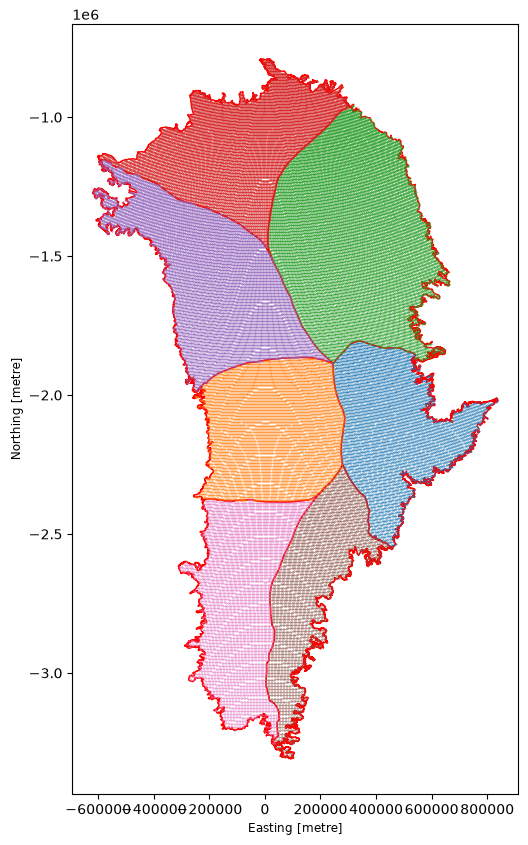

In [43]:
fig, ax = plt.subplots(figsize=(10, 10))

region_projections.plot(
    ax=ax,
    facecolor="none",
    edgecolor="red"
)

era5_regions.plot(
    ax=ax,
    markersize=0.1,
    #color="blue"
    column='label'
)



In [58]:
## Create a mask to be able to just look up the region of any given point

# Make an empty 2D array, with one entry for each ERA5 grid cell.
# -1 means that the grid cell is not in a Mouginot region.
region_mask = np.full(
    (met_data.sizes["latitude"], met_data.sizes["longitude"]),
    'noregion'#-1#,
    #dtype=np.int16
)

print(region_mask[:10])

# Fill the array with the region ID for each matched grid cell.
region_mask[era5_regions["ilat"], era5_regions["ilon"]] = (
    era5_regions['label']#.astype(int)
)
print(region_mask[:10])

# Turn the np array into an xr DataArray.
region_mask_xr = xr.DataArray(
    region_mask,
    coords={
        "latitude": met_data["latitude"],
        "longitude": met_data["longitude"]
    },
    dims=["latitude", "longitude"],
    name="mouginot_region"
)


[['noregion' 'noregion' 'noregion' ... 'noregion' 'noregion' 'noregion']
 ['noregion' 'noregion' 'noregion' ... 'noregion' 'noregion' 'noregion']
 ['noregion' 'noregion' 'noregion' ... 'noregion' 'noregion' 'noregion']
 ...
 ['noregion' 'noregion' 'noregion' ... 'noregion' 'noregion' 'noregion']
 ['noregion' 'noregion' 'noregion' ... 'noregion' 'noregion' 'noregion']
 ['noregion' 'noregion' 'noregion' ... 'noregion' 'noregion' 'noregion']]
[['nan' 'nan' 'nan' ... 'nan' 'nan' 'nan']
 ['nan' 'nan' 'nan' ... 'nan' 'nan' 'nan']
 ['nan' 'nan' 'nan' ... 'nan' 'nan' 'nan']
 ...
 ['nan' 'nan' 'nan' ... 'nan' 'nan' 'nan']
 ['nan' 'nan' 'nan' ... 'nan' 'nan' 'nan']
 ['nan' 'nan' 'nan' ... 'nan' 'nan' 'nan']]


In [59]:
print(np.unique(region_mask))


['CE' 'CW' 'NE' 'NO' 'NW' 'SE' 'SW' 'nan']


In [77]:
# I should be able to calculate the spatial mean now

var = met_data["tp"] # testing with total rpecipitation
var_names = ['t2m', 'strd', 'sp', 'tp']

region_ids = np.unique(era5_regions['label'].dropna())

print(region_ids)

regional_monthly = []

for region_id in region_ids:
    # Select all the ERA5 variables and keep only points in this region
    regional_data = (
        met_data[var_names]
        .where(region_mask_xr == region_id)
        .mean(dim=["latitude", "longitude"])
    )


    # Convert the time series to monthly means
    monthly_data = regional_data.resample(valid_time="MS").mean()

    # Add the region ID as a dimension
    monthly_data = monthly_data.expand_dims(region=[region_id])

    # Store the result
    regional_monthly.append(monthly_data)

# Combine all regions into one Dataset
monthly_means = xr.concat(
    regional_monthly,
    dim="region"
)

#monthly_means.name = f"monthly_mean_{var.name}"

#print(monthly_means)
monthly_means

['CE' 'CW' 'NE' 'NO' 'NW' 'SE' 'SW']


<xarray.Dataset> Size: 111kB
Dimensions:     (region: 7, valid_time: 922)
Coordinates:
  * region      (region) object 56B 'CE' 'CW' 'NE' 'NO' 'NW' 'SE' 'SW'
  * valid_time  (valid_time) datetime64[ns] 7kB 1950-01-01 ... 2026-10-01
    number      int64 8B 0
Data variables:
    t2m         (region, valid_time) float32 26kB 248.1 243.0 ... 259.4 256.6
    strd        (region, valid_time) float32 26kB 1.599e+07 ... 1.733e+07
    sp          (region, valid_time) float32 26kB 7.453e+04 ... 7.8e+04
    tp          (region, valid_time) float32 26kB 0.005364 0.001076 ... 0.001874
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-23T20:52 GRIB to CDM+CF via cfgrib-0.9.1...

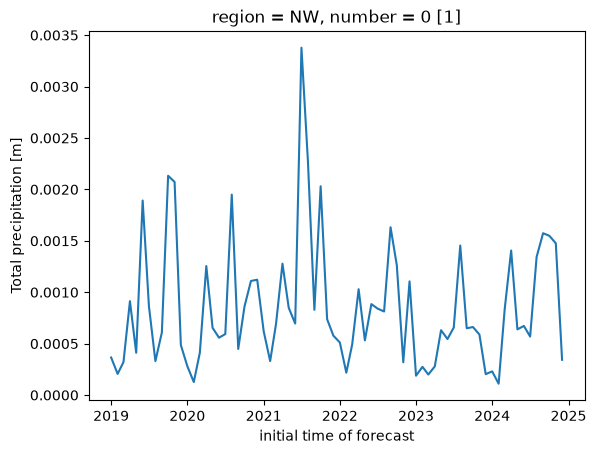

In [78]:
monthly_means['tp'].sel(region='NW', valid_time=slice("2019-01-01", "2024-12-31")).plot()

Text(0.5, 1.0, 'Mean thermal rad')

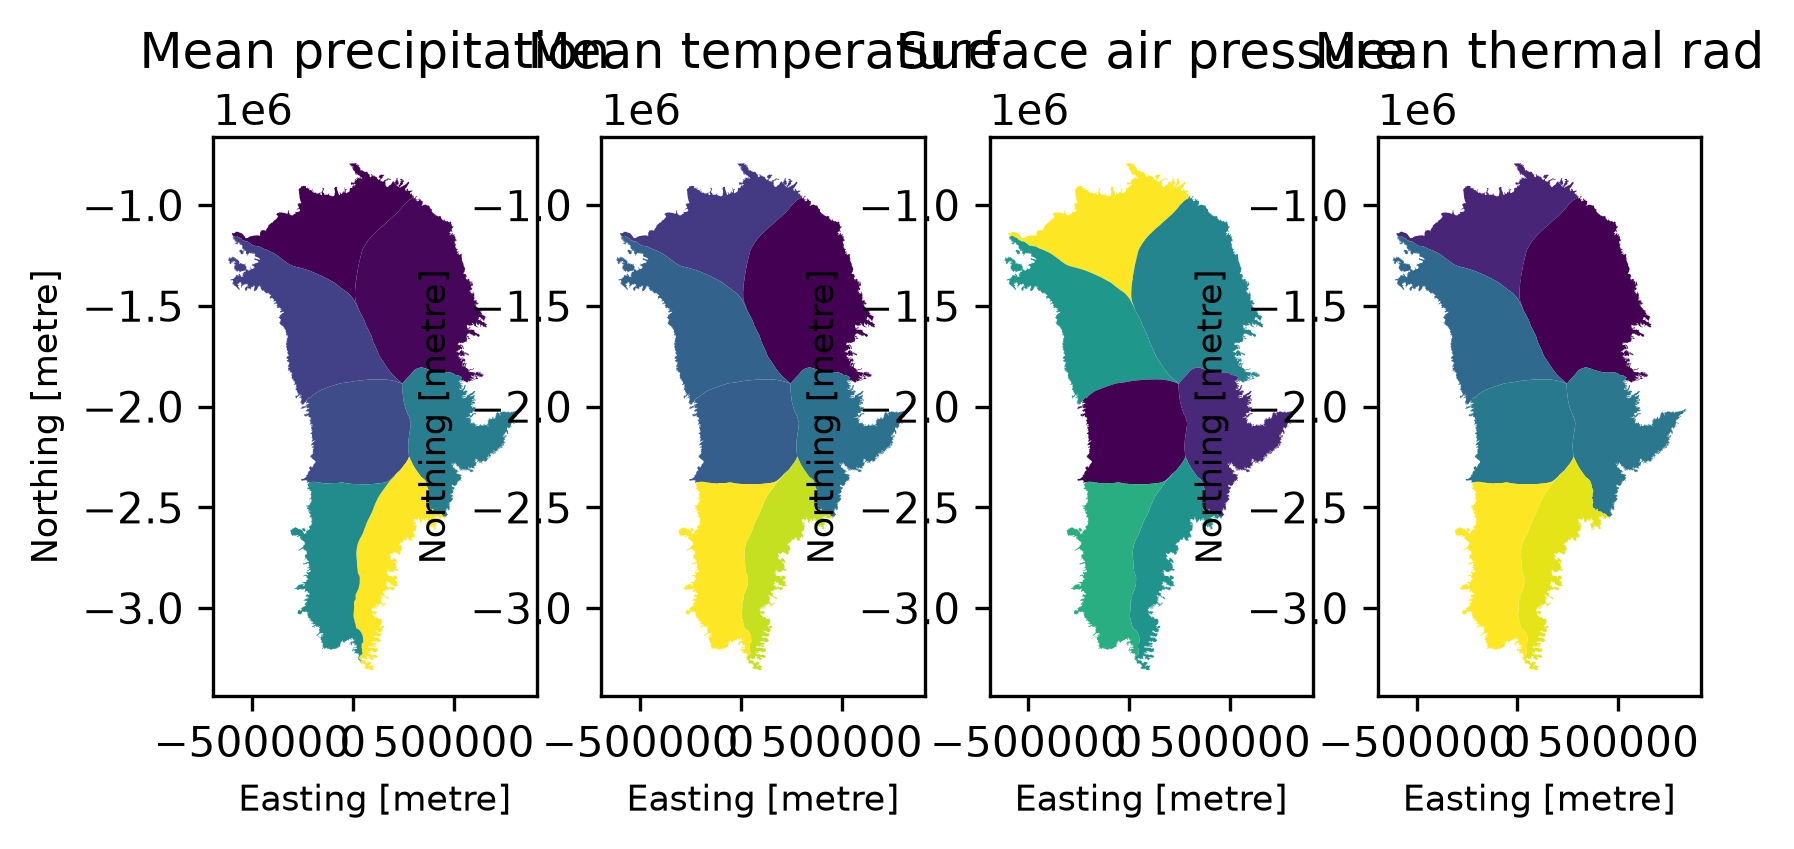

In [107]:
fig, ax = plt.subplots(1,4, dpi=300)

region_projections.plot(
    ax=ax[0],
    column=[monthly_means['tp'].sel(region=region_name, valid_time=slice("2019-01-01", "2024-12-31")).mean(dim='valid_time').values for region_name in region_projections.index.values]
)

ax[0].set_title('Mean precipitation')


region_projections.plot(
    ax=ax[1],
    column=[monthly_means['t2m'].sel(region=region_name, valid_time=slice("2019-01-01", "2024-12-31")).mean(dim='valid_time').values for region_name in region_projections.index.values]
)

ax[1].set_title('Mean temperature')

region_projections.plot(
    ax=ax[2],
    column=[monthly_means['sp'].sel(region=region_name, valid_time=slice("2019-01-01", "2024-12-31")).mean(dim='valid_time').values for region_name in region_projections.index.values]
)

ax[2].set_title('Surface air pressure')

region_projections.plot(
    ax=ax[3],
    column=[monthly_means['strd'].sel(region=region_name, valid_time=slice("2019-01-01", "2024-12-31")).mean(dim='valid_time').values for region_name in region_projections.index.values]
)

ax[3].set_title('Mean thermal rad')

In [86]:
monthly_means['tp'].sel(region=region_id, valid_time=slice("2019-01-01", "2024-12-31")).mean().values

array(0.00157879, dtype=float32)

In [101]:
monthly_means['tp'].sel( valid_time=slice("2019-01-01", "2024-12-31")).mean(dim='valid_time')

<xarray.DataArray 'tp' (region: 7)> Size: 28B
array([0.00142208, 0.00095078, 0.00042792, 0.00038373, 0.00084693,
       0.0028534 , 0.00157879], dtype=float32)
Coordinates:
  * region   (region) object 56B 'CE' 'CW' 'NE' 'NO' 'NW' 'SE' 'SW'
    number   int64 8B 0
Attributes: (12/31)
    GRIB_paramId:                             228
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      189441
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_gridType:                            regular_ll
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               m
    long_name:                                Total precipitation
    units:                                    m
    standard_name:                            unknown
    GRIB_surface:                             0.0

## Train the model
Due to time constraints we're going to use xgboost. Given the relatively large amount of data a NN may be applicable, but this would require a large amount of tuning and testing to ensure that it is working accurately.

In [135]:
# convert the xarray of met data to pandas
era5_df = monthly_means.to_dataframe().reset_index()
era5_df = era5_df.rename(columns={'valid_time':'time'})

# read in the freshwater data (explored in EDA.ipynb)
discharge = xr.open_dataset('DATA/GreenlandData/GL_discharge.nc')
discharge = discharge.set_coords('region_name')

runoff = xr.open_dataset('DATA/GreenlandData/GL_runoff.nc')
runoff = runoff.set_coords('region_name')
total_runoff = ( runoff["surface_runoff_from_ice"]
    + runoff["surface_runoff_from_land"]
    + runoff["subglacial_discharge_from_ice"]
    + runoff["subglacial_discharge_from_land"] )

# Freshwater target
discharge_df = discharge["discharge"].to_dataframe().reset_index()
discharge_df = discharge_df.rename(columns={'region':'region_index', 'region_name':'region'})

runoff_df = runoff.to_dataframe().reset_index()
runoff_df['total'] = runoff_df['surface_runoff_from_ice'] + runoff_df['surface_runoff_from_land'] + runoff_df['subglacial_discharge_from_ice'] + runoff_df['subglacial_discharge_from_land']
runoff_df = runoff_df.rename(columns={'region':'region_index', 'region_name':'region'})


era5_df.head()

,region,time,t2m,strd,sp,tp,number
0,CE,1950-01-01,248.093689,15994120.0,74530.406250,0.005364,0
1,CE,1950-02-01,242.989151,12903594.0,74277.140625,0.001076,0
2,CE,1950-03-01,246.131668,13659244.0,74620.015625,0.000800,0
3,CE,1950-04-01,247.968689,12712504.0,75047.414062,0.000443,0
4,CE,1950-05-01,259.651917,16943792.0,76204.085938,0.001841,0


In [136]:
discharge_df.head()

,region_index,time,region,discharge
0,1,1840-01-01,CE,60.632484
1,1,1841-01-01,CE,60.632484
2,1,1842-01-01,CE,60.632484
3,1,1843-01-01,CE,60.632484
4,1,1844-01-01,CE,60.632484


In [145]:
# merge the met data and freshwater time series into one df
# use separate dfs for runoff and discharge since they have different temporal resolutions
data_runoff = pd.merge(
    era5_df,
    runoff_df,
    on=["time", "region"],
    how="inner"
)
data_discharge = pd.merge(
    era5_df,
    discharge_df,
    on=["time", "region"],
    how="inner"
)

data = data.sort_values(["region", "time"]).reset_index(drop=True)

(data_runoff.head())

,region,time,t2m,strd,sp,tp,number,region_index,subglacial_discharge_from_land,surface_runoff_from_land,subglacial_discharge_from_ice,surface_runoff_from_ice,min_discharge_depth,total
0,CE,1950-01-01,248.093689,15994120.0,74530.406250,0.005364,0,1,2483.524969,3010.292286,6.512867,1.095607,-661.0,5501.425729
1,CE,1950-02-01,242.989151,12903594.0,74277.140625,0.001076,0,1,1906.876758,2327.123164,17.527708,1.383305,-661.0,4252.910934
2,CE,1950-03-01,246.131668,13659244.0,74620.015625,0.000800,0,1,1851.268686,2278.307834,1.823758,0.660118,-661.0,4132.060396
3,CE,1950-04-01,247.968689,12712504.0,75047.414062,0.000443,0,1,1626.203536,2015.828378,1.922482,0.444959,-661.0,3644.399356
4,CE,1950-05-01,259.651917,16943792.0,76204.085938,0.001841,0,1,3101.171603,4902.169453,7499.579634,7693.212427,-661.0,23196.133117


In [147]:
# Make sure the merging and everything here worked
print(data_runoff.isna().sum())
print(data_runoff.groupby("region").size())
print(data_runoff["time"].min(), data_runoff["time"].max())

print('\n')

print(data_discharge.isna().sum())
print(data_discharge.groupby("region").size())
print(data_discharge["time"].min(), data_discharge["time"].max())

region                            0
time                              0
t2m                               0
strd                              0
sp                                0
tp                                0
number                            0
region_index                      0
subglacial_discharge_from_land    0
surface_runoff_from_land          0
subglacial_discharge_from_ice     0
surface_runoff_from_ice           0
min_discharge_depth               0
total                             0
dtype: int64
region
CE    876
CW    876
NE    876
NO    876
NW    876
SE    876
SW    876
dtype: int64
1950-01-01 00:00:00 2022-12-01 00:00:00


region          0
time            0
t2m             0
strd            0
sp              0
tp              0
number          0
region_index    0
discharge       0
dtype: int64
region
CE    76
CW    76
NE    76
NO    76
NW    76
SE    76
SW    76
dtype: int64
1950-01-01 00:00:00 2025-01-01 00:00:00


In [149]:
## Prepare the training features (starting with runoff)
# Feature normalisation would be extremely useful here

# Add month of year
data_runoff["month"] = data_runoff["time"].dt.month

# Represent month cyclically
data_runoff["month_sin"] = np.sin(2 * np.pi * data_runoff["month"] / 12)
data_runoff["month_cos"] = np.cos(2 * np.pi * data_runoff["month"] / 12)

# Add one- and two-month lags for each ERA5 variable
era5_variables = ["t2m", "tp", "sp", "strd"] 

for var in era5_variables:
    data_runoff[f"{var}_lag1"] = (
        data_runoff.groupby("region")[var].shift(1)
    )
    data_runoff[f"{var}_lag2"] = (
        data_runoff.groupby("region")[var].shift(2)
    )
    data_runoff[f"{var}_lag3"] = (
        data_runoff.groupby("region")[var].shift(3)
    )
data_runoff = data_runoff.dropna().reset_index(drop=True)

In [186]:
target = "surface_runoff_from_ice"  # Change to your freshwater variable name

features = (
    era5_variables
    + [f"{v}_lag1" for v in era5_variables]
    + [f"{v}_lag2" for v in era5_variables]
    + ["month_sin", "month_cos"]
)

In [187]:
# Fit a model per region
# A single model taking region as a variable may be interesting but as a first step this is likely to give the best insight for each region

models = {}
results = []

for region_id in sorted(data_runoff["region"].unique()):

    # Select data for this region
    region_data = (
        data_runoff[data_runoff["region"] == region_id]
        .sort_values("time")
        .copy()
    )

    # Identify chronological cut-off dates
    dates = np.sort(region_data["time"].unique())

    train_end = dates[int(len(dates) * 0.70)]
    val_end = dates[int(len(dates) * 0.85)]

    # Split into training, validation and testing periods
    train = region_data[region_data["time"] < train_end]
    validation = region_data[
        (region_data["time"] >= train_end) &
        (region_data["time"] < val_end)
    ]
    test = region_data[region_data["time"] >= val_end]

    X_train = train[features]
    y_train = train[target]

    X_val = validation[features]
    y_val = validation[target]

    X_test = test[features]
    y_test = test[target]

    # Create the XGBoost model
    model = XGBRegressor(
        n_estimators=1000,
        learning_rate=0.03,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        eval_metric="rmse",
        early_stopping_rounds=50,
        random_state=42
    )

    # Train the model
    model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    # Predict freshwater outflow in the test period
    predictions = model.predict(X_test)

    # Calculate performance statistics
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    # Store the model and its results
    models[region_id] = model

    results.append({
        "region": region_id,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "test_start": test["time"].min(),
        "test_end": test["time"].max()
    })

    print(
        f"Region {region_id}: "
        f"MAE={mae:.3f}, RMSE={rmse:.3f}, R²={r2:.3f}"
    )

results_df = pd.DataFrame(results)

Region CE: MAE=6090.475, RMSE=13554.562, R²=0.944
Region CW: MAE=5962.287, RMSE=14084.609, R²=0.892
Region NE: MAE=11529.489, RMSE=30819.090, R²=0.829
Region NO: MAE=9268.574, RMSE=23740.800, R²=0.863
Region NW: MAE=4078.144, RMSE=9539.050, R²=0.855
Region SE: MAE=3694.873, RMSE=6530.044, R²=0.970
Region SW: MAE=19404.698, RMSE=54879.979, R²=0.923


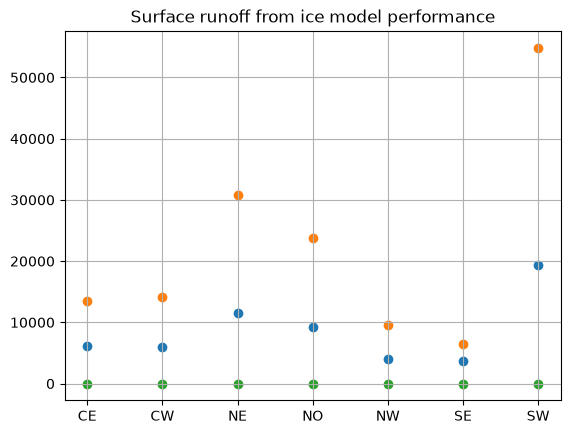

In [188]:
results_df

plt.scatter(results_df.region, results_df.MAE)
plt.scatter(results_df.region, results_df.RMSE)
plt.scatter(results_df.region, results_df.R2)

plt.grid()
plt.title('Surface runoff from ice model performance')
plt.savefig('surfacerunofffromice_modelperformances.png')

Interesting that SW has the worst model performance while SE is very good in comparison with the other regions. Similarly, NW performs better than both other northern regions.

<Axes: title={'center': 'Observed vs predicted freshwater outflow - Region SW'}, xlabel='time', ylabel='Freshwater outflow'>

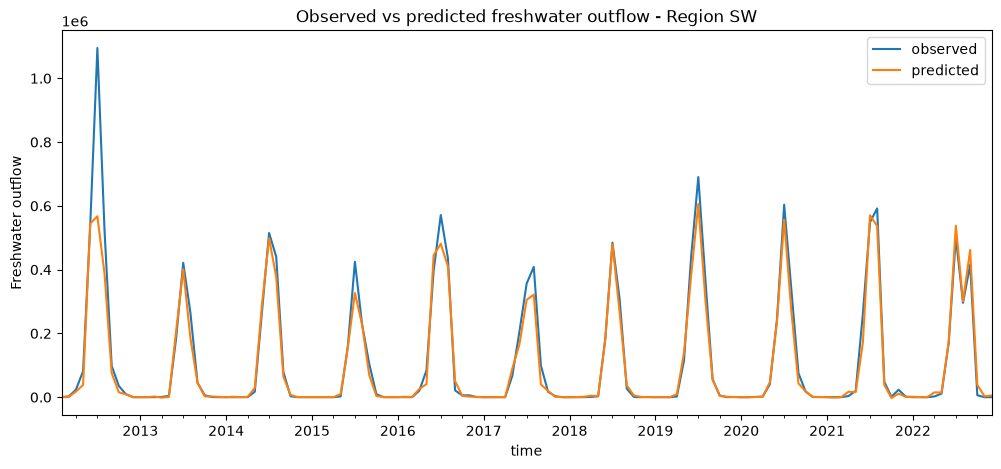

In [189]:
# Plot the prediction vs test to investigate visually
val_end = dates[int(len(dates) * 0.85)]

test = region_data[region_data["time"] >= val_end]

model = models[region_id]

predictions = model.predict(test[features])

comparison = pd.DataFrame({
    "time": test["time"],
    "observed": test[target],
    "predicted": predictions
})

comparison = comparison.set_index("time")

comparison.plot(
    figsize=(12, 5),
    title=f"Observed vs predicted freshwater outflow - Region {region_id}",
    ylabel="Freshwater outflow"
)

The seasonal peaks are captured often not very accurately (and chronically under-estimated). The model is likely learning the seasonal pattern but not any smaller variability based on meteorological conditions.  

Text(0.5, 0, 'Feature importance')

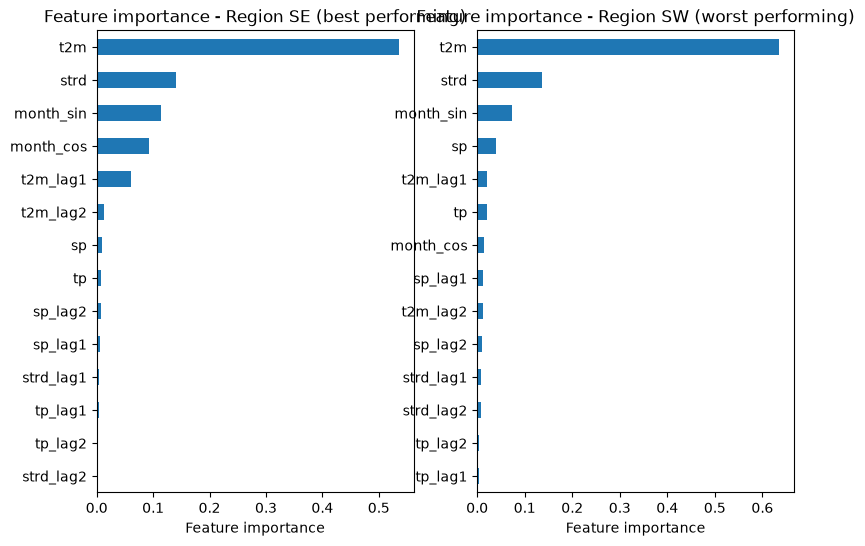

In [190]:
fig, ax = plt.subplots(1,2, figsize=(20,8))

region = 'SE'
model = models[region]

importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values()

importance.plot(
    kind="barh",
    figsize=(9, 6),
    title=f"Feature importance - Region {region} (best performing)",
    ax=ax[0]
)

ax[0].set_xlabel("Feature importance")

region = 'SW'
model = models[region]

importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values()

importance.plot(
    kind="barh",
    figsize=(9, 6),
    title=f"Feature importance - Region {region} (worst performing)",
    ax=ax[1]
)

ax[1].set_xlabel("Feature importance")

The air temperature is (significantly) the most important predictor for the models, with lagged values (corresponding to lead time conditions) factoring only extremely minorly. The only lag to feature non-negligibly is the temperature. This holds for all regions and all four liguid runoff variables. This is surprising, and further investigation is required to determine teh exact dependence on temperature.

## Model the solid discharge

In [191]:
# Add month of year
data_discharge["month"] = data_discharge["time"].dt.month

# Represent month cyclically
data_discharge["month_sin"] = np.sin(2 * np.pi * data_discharge["month"] / 12)
data_discharge["month_cos"] = np.cos(2 * np.pi * data_discharge["month"] / 12)

# Add one- and two-month lags for each ERA5 variable
era5_variables = ["t2m", "tp", "sp", "strd"] 

for var in era5_variables:
    data_discharge[f"{var}_lag1"] = (
        data_discharge.groupby("region")[var].shift(1)
    )
    data_discharge[f"{var}_lag2"] = (
        data_discharge.groupby("region")[var].shift(2)
    )
    data_discharge[f"{var}_lag3"] = (
        data_discharge.groupby("region")[var].shift(3)
    )
data_discharge = data_discharge.dropna().reset_index(drop=True)

In [192]:
target = "discharge"  # Change to your freshwater variable name

features = (
    era5_variables
    + [f"{v}_lag1" for v in era5_variables]
    + [f"{v}_lag2" for v in era5_variables]
    + ["month_sin", "month_cos"]
)

In [193]:
# Fit a model per region
# A single model taking region as a variable may be interesting but as a first step this is likely to give the best insight for each region

models = {}
results = []

for region_id in sorted(data_discharge["region"].unique()):

    # Select data for this region
    region_data = (
        data_discharge[data_discharge["region"] == region_id]
        .sort_values("time")
        .copy()
    )

    # Identify chronological cut-off dates
    dates = np.sort(region_data["time"].unique())

    train_end = dates[int(len(dates) * 0.70)]
    val_end = dates[int(len(dates) * 0.85)]

    # Split into training, validation and testing periods
    train = region_data[region_data["time"] < train_end]
    validation = region_data[
        (region_data["time"] >= train_end) &
        (region_data["time"] < val_end)
    ]
    test = region_data[region_data["time"] >= val_end]

    X_train = train[features]
    y_train = train[target]

    X_val = validation[features]
    y_val = validation[target]

    X_test = test[features]
    y_test = test[target]

    # Create the XGBoost model
    model = XGBRegressor(
        n_estimators=1000,
        learning_rate=0.03,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        eval_metric="rmse",
        early_stopping_rounds=50,
        random_state=42
    )

    # Train the model
    model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    # Predict freshwater outflow in the test period
    predictions = model.predict(X_test)

    # Calculate performance statistics
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    # Store the model and its results
    models[region_id] = model

    results.append({
        "region": region_id,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "test_start": test["time"].min(),
        "test_end": test["time"].max()
    })

    print(
        f"Region {region_id}: "
        f"MAE={mae:.3f}, RMSE={rmse:.3f}, R²={r2:.3f}"
    )

results_df = pd.DataFrame(results)

Region CE: MAE=17.488, RMSE=22.803, R²=-0.034
Region CW: MAE=18.231, RMSE=24.174, R²=-0.072
Region NE: MAE=11.729, RMSE=13.192, R²=-0.564
Region NO: MAE=5.334, RMSE=7.862, R²=-0.028
Region NW: MAE=30.212, RMSE=35.170, R²=-0.158
Region SE: MAE=26.657, RMSE=41.711, R²=-0.044
Region SW: MAE=2.446, RMSE=5.566, R²=-0.205


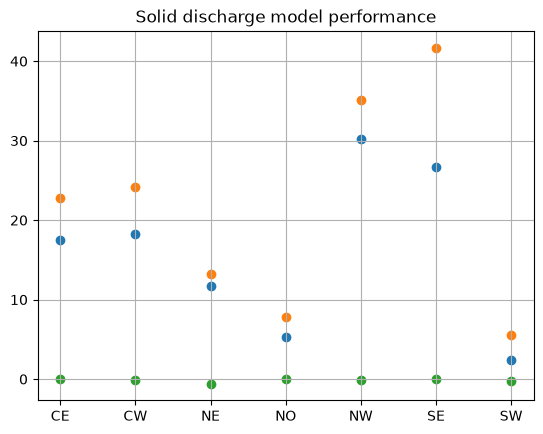

In [194]:
plt.scatter(results_df.region, results_df.MAE)
plt.scatter(results_df.region, results_df.RMSE)
plt.scatter(results_df.region, results_df.R2)

plt.grid()
plt.title('Solid discharge model performance')
plt.savefig('soliddischarge_modelperformances.png')

Text(0.5, 0, 'Feature importance')

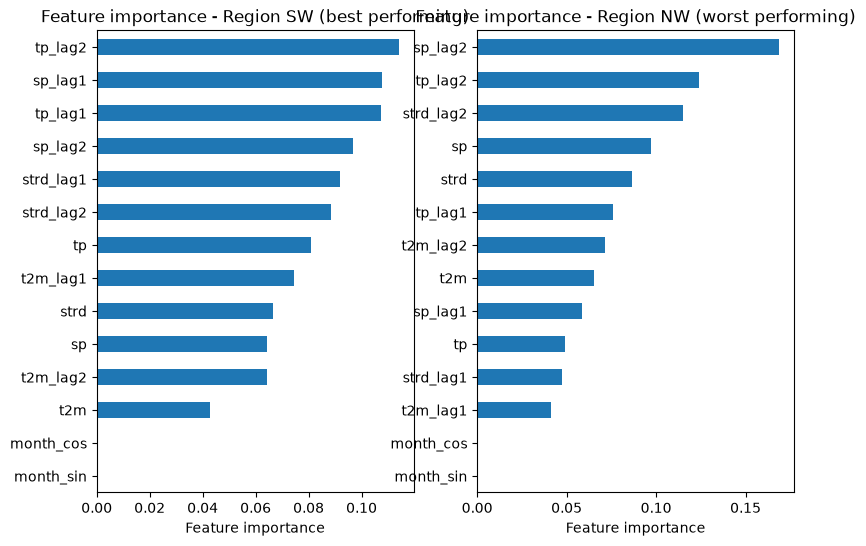

In [195]:
fig, ax = plt.subplots(1,2, figsize=(20,8))

region = 'SW'
model = models[region]

importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values()

importance.plot(
    kind="barh",
    figsize=(9, 6),
    title=f"Feature importance - Region {region} (best performing)",
    ax=ax[0]
)

ax[0].set_xlabel("Feature importance")

region = 'NW'
model = models[region]

importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values()

importance.plot(
    kind="barh",
    figsize=(9, 6),
    title=f"Feature importance - Region {region} (worst performing)",
    ax=ax[1]
)

ax[1].set_xlabel("Feature importance")

Very promising that the model identified the lagged variables as significantly more important for solid discharge than for liquid discharge. This makes intuitive sense, and provides an excellent place for a more detailed study. For both solid and liquid models, I would be very interested to determine the cause of the difference in accuracy between the models for different regions. 

The first avenue fo investigation for this question would be to determine the change or anomaly in freshwater output of the poorly performing regions. It may be that these regions have changed their discharge more between training and test times than the well-performing models, or that the poorly-performing models have more extreme values in their test sets that are being badly predicted. 

The fact that the best and worst performing regional models have very similar importance breakdowns is notable. This suggests that this study is not accounting for a significant factor at play in the freshwater output. To investigate this, first other ERA5 variables should be included (particularly evaporation for the liquid model) and their effects determined.

Despite these drawbacks and time constraints pf this version of the model, this is a very useful starting point for further study of the link between freshwater and meteorological conditions, while already providing some insight into the different behaviours of the solid and liquid discharge.
